<a href="https://colab.research.google.com/github/PpaulaPulido/ConnectCargo/blob/main/FIFA21_RandomForest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Valor de jugadores FIFA 21
Ejecuta los bloques en orden. Si Colab lo solicita, sube `datos_limpios_inteligentes.csv`. El índice original empieza en 0.

In [1]:
# Bloque 1. Librerías y carga de datos
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split

ruta = Path("datos_limpios_inteligentes.csv")
if not ruta.exists():
    from google.colab import files

    files.upload()

df = pd.read_csv(ruta)
print(f"Datos cargados: {df.shape[0]:,} filas y {df.shape[1]} columnas")

Saving datos_limpios_inteligentes.csv to datos_limpios_inteligentes.csv
Datos cargados: 18,979 filas y 87 columnas


In [2]:
# Bloque 2. Variable objetivo y variables predictoras
y = df['Value']
X = df.drop(columns=['Value', 'Wage', 'Release Clause'], errors='ignore')

In [3]:
# Bloque 3. División en entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [4]:
# Bloque 4. Entrenamiento y predicción
modelo = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
modelo.fit(X_train, y_train)
y_pred = modelo.predict(X_test)

In [5]:
# Bloque 5. Evaluación
def euros(valor):
    importe = f"{abs(valor):,.2f}".replace(",", "_").replace(".", ",").replace("_", ".")
    signo = "-" if valor < 0 else ""
    return f"{signo}€{importe}"

r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
print(f"R²: {r2:.6f}")
print(f"MAE: {euros(mae)}")

R²: 0.985747
MAE: €175.224,71


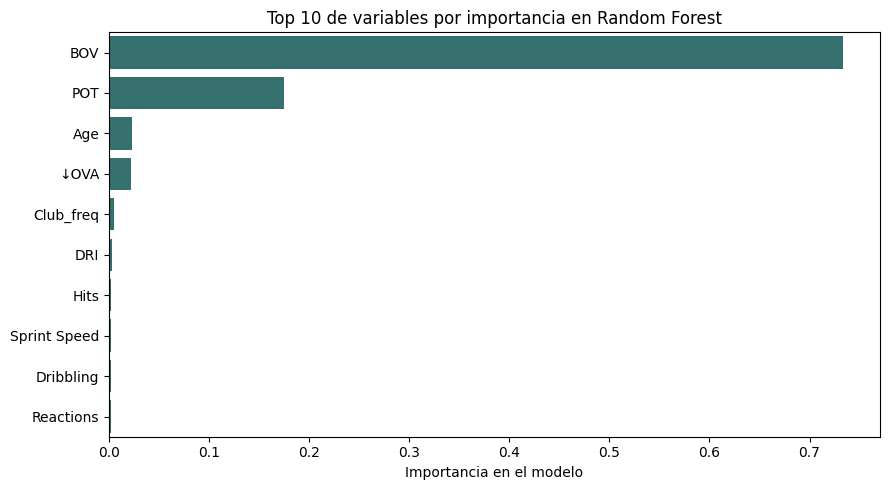

In [6]:
# Bloque 6. Top 10 de importancia de variables
importancias = pd.DataFrame({
    "Variable": X.columns,
    "Importancia": modelo.feature_importances_,
})
top_10 = importancias.nlargest(10, "Importancia")

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=top_10, x="Importancia", y="Variable", color="#2B7A78", ax=ax)
ax.set(title="Top 10 de variables por importancia en Random Forest",
       xlabel="Importancia en el modelo", ylabel="")
fig.tight_layout()
plt.show()

In [7]:
# Bloque 7. Buscador de gangas
resultados = y_test.rename("Precio Real").to_frame()
resultados["Precio IA"] = pd.Series(y_pred, index=X_test.index)
resultados["Diferencia"] = resultados["Precio IA"] - resultados["Precio Real"]
resultados.index.name = "Índice original"

gangas = resultados.loc[resultados["Diferencia"] > 0].nlargest(5, "Diferencia")
sobrevalorados = resultados.loc[resultados["Diferencia"] < 0].nsmallest(5, "Diferencia")

print("TOP 5 JUGADORES INFRAVALORADOS (GANGAS)")
display(gangas.apply(lambda columna: columna.map(euros)))

print("TOP 5 JUGADORES SOBREVALORADOS")
display(sobrevalorados.apply(lambda columna: columna.map(euros)))

TOP 5 JUGADORES INFRAVALORADOS (GANGAS)


,Precio Real,Precio IA,Diferencia
Índice original,,,
0,"€103.500.000,00","€120.415.000,00","€16.915.000,00"
103,"€66.500.000,00","€80.405.000,00","€13.905.000,00"
38,"€26.000.000,00","€37.500.000,00","€11.500.000,00"
46,"€26.000.000,00","€37.115.000,00","€11.115.000,00"
420,"€27.500.000,00","€38.305.000,00","€10.805.000,00"


TOP 5 JUGADORES SOBREVALORADOS


,Precio Real,Precio IA,Diferencia
Índice original,,,
3,"€129.000.000,00","€107.475.000,00","-€21.525.000,00"
31,"€95.000.000,00","€79.900.000,00","-€15.100.000,00"
536,"€39.500.000,00","€30.775.000,00","-€8.725.000,00"
72,"€62.000.000,00","€53.465.000,00","-€8.535.000,00"
50,"€61.500.000,00","€53.125.000,00","-€8.375.000,00"
